<center><h1>Principal Component Analysis</h1></center>
<center><h4>EigenVectors and EigenValues as a crucial step</h4></center>

Eigenvectors and Eigenvalues are special numbers and vectors where, eigenvectors are special vectors who cant change their direction when a matrix transformation is applied to it and eigenvalues are the values that tell how scaled that vector is.

At first look this doesent appear too important, but its a powerful technique when you look at it deeper.

<center><h4>Problem setting</h4></center>

Let's forget for a second real engineering problems, and use a simple example. Say in front of you, on the ground you see spread out chocholate chips, lets say its in the form of this graph and we imagine were standing over it and looking at it hence 2D for simplicity:

<p style="text-align: center;">
    <img src="../images/variance.png">
</p>

But for convenience lets say these are magic chocolate chips, and once spilt most of them are actually floating at different heights, so what you get is 3D.

So you circle around the chips, you look straight from the back it looks like an ellipse(imagine looking at the chips spread as a grain of rice shape and when you look at it from the holes it looks like a circle). Same with the front, you look from the side it looks like a rectangle somewhat still but short and finally from the top it looks like a rectangle somewhat still but longer and wider.

Intuitively you can say that this gives you the best perspective. Beacuse it captures mostly of about how the rice grain shape looks like in 3D, aka gives you most information.

 Looking at the ground(graph) from straight above we can see that the chips are spilled over going from bottom left to top right from our perspective. Now someone asks you `what direction have the chips been spilled towards`. You look at it and say well someone must have been walking diagonally from this direction and spilled them diagonally to this perspective. And thats correct, and the way we know this is you can obviously see with your eyes their direction.  

Now someone asks you ok but that is a vague answer, tell me the exact direction, and you draw a line sort of shadow on the ground(aka vector) going along the long direction of the chips from bottom left to top right, and you say there it is. Now someone else draws another line very similar to yours and you two debate which one is the more accurate one.   

Well how do you actually measure the accuracy? Well there exists a tool very specific to this, what you do is for both lines you both have drawn, you measure the distance as a straigh line of each single chip on the ground twice(once to your line and the other straight line). In the fashion of this(ignore everything except the dashed lines to the main line):

<p style="text-align: center;">
    <img src="../images/error_distance.png">
</p>

Those dashed lines represent each individual error to one of the lines respectively for each chip(aka how far off it is). And what you do is you take all of those values together firstly square them(penalizing larger misses more than smaller, and other reasons) then divide them by total number of chips and you have the actual error(Mean Squared Error) for that particular line. You compare and say the true value is the more accurate one(aka one with least error). You do this many times and eventually you find the best fit line.

And after that the person whose chocolate chips got spilt comes and asks, which direction where my chocolate chips spilled? You can confidently say the line on the ground that is right in the area of the chips, is the actual direction. And you only show him the line on the ground. And the person immediatly knows beacuse he can see the direction without looking at the chips floating in a tube shape and inspecting it from all angles. What you just did was store information from a 3D world into a simple 2D.

So after all this measuring you step back and think, how did the simple act of minimizing the distances to an arbitrary line actually give me the exact same information, and make it easier to work with(explaining the direction to the person with a simple line)?

Well it all comes to variance. Mathematically the minimization of MSE is equivalent to the maximization of variance. When we talked about looking at the tube from different angles, what changed with each angle was the variance we saw from that specific perspective.

So variance tell's us how informative something is. 

<p style="text-align: center;">
    <img src="../images/eigenvector.png">
</p>

For each chip, the distance from the center is fixed aka it doesn't care which line you drew. That distance is the hypotenuse. Split it into "how far along the line" and "how far off the line," and Pythagoras gives:

$$ \|\mathbf{x}\|^{2} = \|\tilde{\mathbf{x}}\|^{2} + \|\mathbf{x} - \tilde{\mathbf{x}}\|^{2} $$

* **$\|\mathbf{x}\|^{2}$** – this is the hypothenuse, which always has the same value
* **$\|\tilde{\mathbf{x}}\|^{2}$** – this is spread, the distance from center to where the point falls on the line
* **$\|\mathbf{x} - \tilde{\mathbf{x}}\|^{2}$** – distance is the error


This in essence is how Principal Component Analysis with MSE is applied. However actual application does it with variance maximization.

In [239]:
"""
    Principal Component Analysis (PCA) from scratch.
    
    The mathematical model in this notebook is derived from the Mathematics for Machine Learning book by Marc Peter Deisenroth, A. Aldo Faisal, and Cheng Soon Ong.
    Specifically chapter 10, which is dedicated to PCA. The book is available for free online at https://mml-book.github.io/book/mml-book.pdf.

    NOTE: this part for the data is AI Generated 
"""
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
N = 200

# 1. axis-aligned cloud: long, medium, flat — a stepped-on grain of rice
scales = np.array([3.0, 1.0, 0.6])
X = rng.normal(0, 1, size=(N, 3)) * scales

# 2. rotate about TWO axes so no principal direction lands on a coordinate axis
tz, tx = np.deg2rad(30), np.deg2rad(50)
Rz = np.array([[np.cos(tz), -np.sin(tz), 0],
               [np.sin(tz),  np.cos(tz), 0],
               [0,           0,          1]])
Rx = np.array([[1, 0,           0],
               [0, np.cos(tx), -np.sin(tx)],
               [0, np.sin(tx),  np.cos(tx)]])
R = Rx @ Rz
X = X @ R.T

# 3. shove it off-origin, so you have to center it yourself
X += np.array([4.0, -2.0, 1.0])

# ground truth for later checking
true_eigvals = np.sort(scales ** 2)[::-1]   # [2.53, 0.28, 0.19]
true_axes = R                                # columns are the true principal directions

In [240]:
"""
    Sanity check for data
"""
X[:5]

array([[ 5.31167025, -2.6300532 ,  0.94962871],
       [ 7.41917641, -1.58069209,  0.28421269],
       [ 4.49026041, -2.04505929,  0.93061765],
       [ 1.34402788, -2.69044819,  0.90317355],
       [ 3.60793218, -1.52371238,  2.00400674]])

In [241]:
"""
    Standardization step for the data:
    
    PCA is sensitive to the scale and size difference between the features of the data, 
    so we need to standardize it before applying PCA. 
    This involves centering the data by subtracting the mean and scaling it by
    dividing by the standard deviation.
"""

def standardize(X):
    """
        Standardizes the data by centering and scaling.
        
        Parameters:
            X (numpy.ndarray): The input data to be standardized.
        
        Returns:
            numpy.ndarray: The standardized data.
    """
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    return (X - mean) / std


standardized_X = standardize(X)

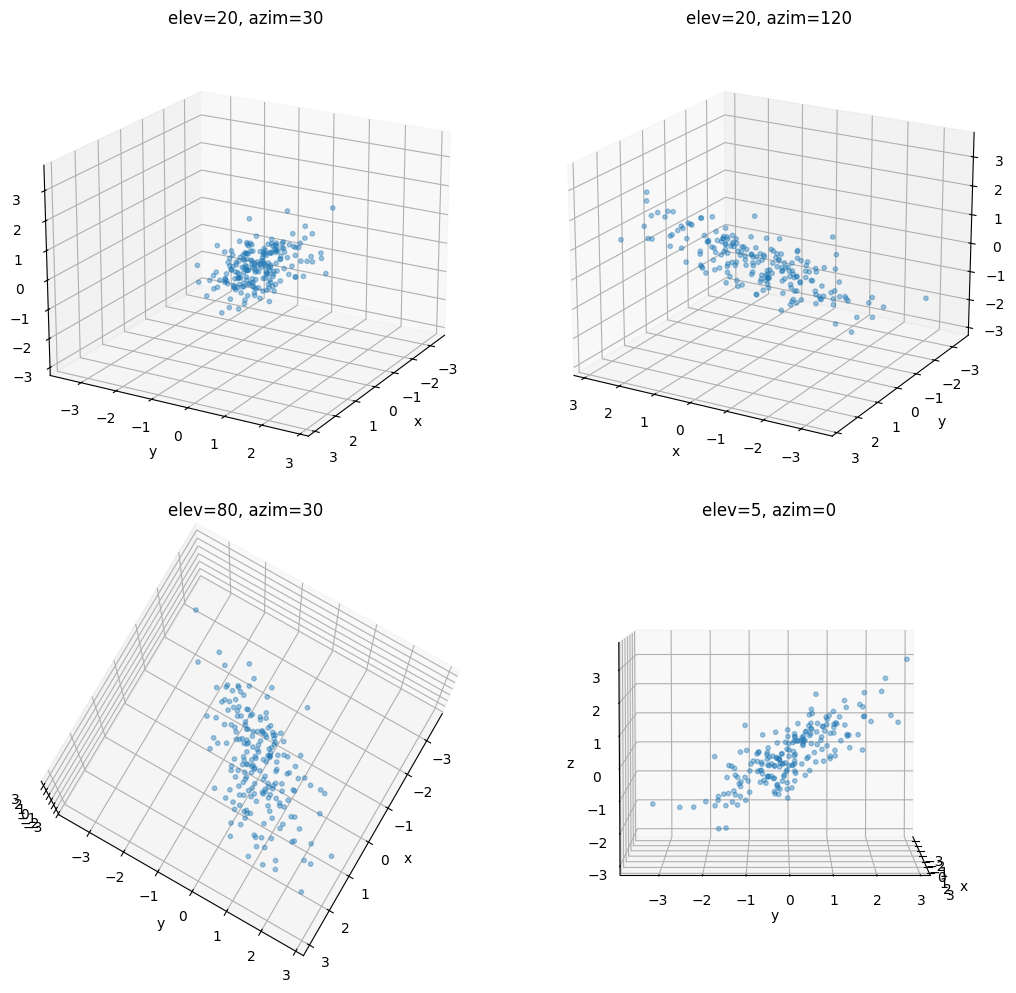

In [242]:
def set_axes_equal(ax):
    """Force equal aspect on a 3D axis — matplotlib won't do this for you."""
    limits = np.array([ax.get_xlim3d(), ax.get_ylim3d(), ax.get_zlim3d()])
    center = limits.mean(axis=1)
    radius = 0.5 * np.max(limits[:, 1] - limits[:, 0])
    for setter, c in zip([ax.set_xlim3d, ax.set_ylim3d, ax.set_zlim3d], center):
        setter(c - radius, c + radius)


Xc = standardized_X - standardized_X.mean(axis=0)

# four viewing angles — walk around the cloud like the chocolate chip story
views = [(20, 30), (20, 120), (80, 30), (5, 0)]

fig = plt.figure(figsize=(11, 10))
for i, (elev, azim) in enumerate(views, 1):
    ax = fig.add_subplot(2, 2, i, projection='3d')
    ax.scatter(Xc[:, 0], Xc[:, 1], Xc[:, 2], s=10, alpha=0.4)
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_title(f'elev={elev}, azim={azim}')
    set_axes_equal(ax)

plt.tight_layout()
plt.show()

In [243]:
"""
    After standardization, we can compute the covariance matrix of the standardized data.
    
    The reason for computing the covariance matrix is to understand how the features of the data vary with respect to each other.
    And the covariance matrix is a key component in PCA, 
    as it helps us identify the directions (principal components) along which the data varies the most.
    
    The covariance matrix is a square matrix that contains the covariances between pairs of features in the data.
    In simpler terms, it tells us how much two features change together. 
    A positive covariance indicates that the features tend to increase or decrease together, 
    while a negative covariance indicates that one feature tends to increase when the other decreases.
"""

def compute_covariance_matrix(X):
    """
        Computes the covariance matrix of the input data.
        
        Parameters:
            X (numpy.ndarray): The input data for which to compute the covariance matrix.
        
        Returns:
            numpy.ndarray: The covariance matrix of the input data.
    """
    n_samples = X.shape[0]
    return (X.T @ X) / (n_samples)

covariance_matrix = compute_covariance_matrix(standardized_X)

covariance_matrix

array([[1.        , 0.75166123, 0.73370993],
       [0.75166123, 1.        , 0.81293963],
       [0.73370993, 0.81293963, 1.        ]])

In [244]:
def power_iteration(S, iters=500, tol=1e-12):
    """
    Find the direction S(matrix) stretches the most.
    
    English:  start with a random direction. Multiply by S. Rescale to
              length 1. Repeat until the direction stops changing.
    Math:     v ← Sv / ‖Sv‖   then   λ = vᵀSv
    
    Returns: (eigenvalue: float, eigenvector: 1D array shape (D,))
    """
    
    # 1. start with a random direction
    v = np.random.rand(S.shape[0])
    v /= np.linalg.norm(v)

    for _ in range(iters):
        # 2. multiply by S
        Sv = S @ v
        
        # 3. rescale to length 1
        v_new = Sv / np.linalg.norm(Sv)
        
        # 4. check for convergence
        v = v_new
        
        if np.linalg.norm(v_new - v) < tol:
            break
        
        

    # 5. compute the corresponding eigenvalue
    eigenvalue = v.T @ S @ v
    
    return eigenvalue, v
    

eigenvalue, eigenvector = power_iteration(covariance_matrix)
print("Eigenvalue:", eigenvalue)
print("Eigenvector:", eigenvector)
    

Eigenvalue: 2.5278158048382973
Eigenvector: [0.56320976 0.5533767  0.61365218]


$$S\mathbf{v} = \lambda \mathbf{v}$$

In [ ]:
def compute_eigen(S, M=None):
    """
    Get the top M eigenpairs, largest eigenvalue first.
    
    English:  find the biggest direction. Erase it from S. Find the biggest
              of what's left. Repeat M times.
    Math:     S' = S − λvvᵀ
    
    Returns: (eigvals: shape (M,), eigvecs: shape (D, M) — vectors as COLUMNS)
    """
    D = S.shape[0]
    if M is None:
        M = D

    eigvals = np.zeros(M)
    eigvecs = np.zeros((D, M))

    for m in range(M):
        # 1. find the biggest direction
        eigval, eigvec = power_iteration(S)
        
        # 2. store the eigenvalue and eigenvector
        eigvals[m] = eigval
        eigvecs[:, m] = eigvec
        
        # 3. erase it from S
        S -= eigval * np.outer(eigvec, eigvec)

    return eigvals, eigvecs